# NewsBias Sentence
### Independent sentence-level spin detection

We fine-tune a general pretrained **Ettin-400M** encoder on the project's deduplicated BABE, MBIC, and lexical BASIL annotations. The output classes are **non-biased** and **biased**. No existing bias classifier supplies training targets.

**Architecture:** bidirectional encoder → masked mean pooling → GELU classification head → two logits.

**Session protocol:** upload the immutable `payload.zip` and the previous `resume.zip`, run this notebook for a 15-minute budget, download the new archive, and continue in a fresh runtime. Optimizer boundaries, shuffled-example position, validation progress, and random states are preserved. GPU numerical results can vary across hardware.

Prepare inputs with `notebooks/scripts/prepare.py`. Use `development` for random example splits across outlets; use a separate `full` payload with the selected epoch count for the final all-records refit.

In [1]:
import os
import time
from pathlib import Path

SESSION_STARTED = float(os.environ.get('NEWSBIAS_SESSION_STARTED', time.monotonic()))
HEADLESS = os.environ.get('NEWSBIAS_HEADLESS') == '1'
ACTION = os.environ.get('NEWSBIAS_ACTION', 'train')
print(f'Sentence specialist · {ACTION} · 15-minute resumable session')

Sentence specialist · train · 15-minute resumable session


## 1. Runtime and uploaded inputs
The CLI stages all data, pretrained weights, and source code before execution. For interactive use, upload `payload.zip` and optionally `resume.zip` first. The model is loaded locally from the payload; a resume archive replaces it with your own trained weights.

In [2]:
import json
import subprocess
import sys
import zipfile

RUNTIME_ROOT = Path('/kaggle/working') if Path('/kaggle/working').exists() else Path('/content') if Path('/content').exists() else Path.cwd()
INPUT_ROOT = Path(os.environ.get('NEWSBIAS_INPUT_ROOT', RUNTIME_ROOT / 'newsbias-inputs'))
OUTPUT_ROOT = Path(os.environ.get('NEWSBIAS_OUTPUT_ROOT', RUNTIME_ROOT / 'outputs'))
if not (INPUT_ROOT / 'config.json').exists():
    candidates = [RUNTIME_ROOT / 'payload.zip', *Path('/kaggle/input').glob('**/payload.zip')]
    payload = next((path for path in candidates if path.is_file()), None)
    if payload is None:
        raise FileNotFoundError('Upload or mount the prepared payload.zip before running.')
    INPUT_ROOT.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(payload) as archive:
        if any(not (INPUT_ROOT / item.filename).resolve().is_relative_to(INPUT_ROOT.resolve()) for item in archive.infolist()):
            raise ValueError('Invalid input archive path')
        archive.extractall(INPUT_ROOT)
if not HEADLESS:
    requirements = json.loads((INPUT_ROOT / 'requirements.json').read_text())
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', *requirements], check=True)
sys.path.insert(0, str(INPUT_ROOT))

import pandas as pd
import torch
from scripts.training import SessionTrainer, TrainingConfig, plot_history

if HEADLESS and not torch.cuda.is_available():
    raise RuntimeError('The headless training worker requires the allocated CUDA GPU.')
print('GPU:', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU')
print('PyTorch:', torch.__version__)

GPU: Tesla T4
PyTorch: 2.11.0+cu130


## 2. Frozen experiment recipe
The payload controls label maps, data membership, and hyperparameters. Changing those settings requires a new experiment rather than resuming an existing optimizer. Natural cross-entropy is the default; source-aware weighting is an explicit configuration option. Dynamic padding, mixed precision, gradient checkpointing, and gradient accumulation reduce memory use.

In [3]:
from dataclasses import asdict

config = TrainingConfig(**json.loads((INPUT_ROOT / 'config.json').read_text()))
assert config.task == 'sentence', 'This notebook requires a sentence payload.'
prepared = json.loads((INPUT_ROOT / 'data.json').read_text())
display(pd.Series(asdict(config), name='Value').to_frame())
distribution = pd.DataFrame([
    {'split': split, 'label': label, 'count': sum(row['label'] == label for row in rows)}
    for split, rows in prepared['splits'].items() for label in config.labels
])
display(distribution.pivot(index='split', columns='label', values='count'))
del prepared

,Value
task,sentence
mode,development
base_model,jhu-clsp/ettin-encoder-400m
model_revision,None
seed,42
split_seed,42
epochs,5
batch_size,4
accumulation_steps,8
encoder_lr,0.00001


label,biased,non-biased
split,,
test,447,1861
train,1563,6515
validation,223,931


## 3. Model and training state
The sentence backbone has 28 layers and 1,024-dimensional hidden states. All encoder layers and the binary classifier are trainable. AdamW uses separate encoder/head learning rates, linear warmup/decay, and gradient clipping. The scheduler spans the entire experiment, not one session.

In [4]:
resume_path = Path(os.environ.get('NEWSBIAS_RESUME', RUNTIME_ROOT / 'resume.zip'))
if not resume_path.exists():
    mounted = list(Path('/kaggle/input').glob('**/resume.zip'))
    resume_path = mounted[0] if len(mounted) == 1 else resume_path
trainer = SessionTrainer(
    config, INPUT_ROOT / 'data.json', OUTPUT_ROOT,
    resume_archive=resume_path if resume_path.exists() else None,
    initial_model=INPUT_ROOT / 'pretrained',
)
display(pd.Series(trainer.describe(), name='Value').to_frame())
if HEADLESS:
    import shutil
    shutil.rmtree(INPUT_ROOT / 'pretrained', ignore_errors=True)
print(trainer.model.classifier)

,Value
task,sentence
mode,development
device,cuda
precision,fp16
parameters,395833346
training_examples,8078
validation_examples,1154
effective_batch,32
total_optimizer_steps,1265
resumed_optimizer_step,573


Linear(in_features=1024, out_features=2, bias=True)


## 4. Execute one bounded slice
The loop reserves 90 seconds for export and pauses at an optimizer boundary. Partial validation is resumed too. The 15-minute budget includes setup inside the execution process; provider queueing and upload/download time are additional. A single slow step or checkpoint write can exceed the soft deadline.

Test evaluation is a separate, explicitly selected action after recipe selection. It also saves progress across slices. Full-data runs have no independent validation/test score.

In [5]:
if ACTION == 'train':
    result = trainer.run(session_started_at=SESSION_STARTED)
elif ACTION == 'evaluate':
    result = trainer.evaluate_test(OUTPUT_ROOT, session_started_at=SESSION_STARTED)
else:
    raise ValueError(f'Unknown action: {ACTION}')
display(pd.Series({key: value for key, value in result.items() if key != 'history'}, name='Result').to_frame())

epoch=3/5 phase=train step=585/1265 batch=664/2020


epoch=3/5 phase=train step=598/1265 batch=768/2020


epoch=3/5 phase=train step=611/1265 batch=872/2020


epoch=3/5 phase=train step=624/1265 batch=976/2020


epoch=3/5 phase=train step=637/1265 batch=1080/2020


epoch=3/5 phase=train step=650/1265 batch=1184/2020


... (7 outputs left out)

epoch=3/5 phase=train step=754/1265 batch=2016/2020


{"epoch": 3, "train_loss": 0.12330006294977995, "val_macro_f1": 0.817832618590334, "val_accuracy": 0.8960138648180243}


Saved /content/outputs/resume.zip; phase=complete; step=755


,Result
status,complete
epoch,3
batch_cursor,0
global_step,755
total_steps,1265
best_macro_f1,0.825859
fingerprint,8f4c6dab866e652acc4673cb8f9315a328ba0d8c2430e1...
archive,resume.zip
checkpoint_seconds,198.36


## 5. Training curves and checkpoint export
Validation macro-F1 selects the best development checkpoint. Use `best_model/selection.json` inside the archive to obtain its epoch count for a new full-data refit. `resume.zip` contains weights, tokenizer, optimizer, scheduler, scaler, RNG states, progress, and the selected checkpoint.

,epoch,train_loss,val_macro_f1,val_accuracy
0,1,0.495993,0.825859,0.885615
1,2,0.302225,0.822946,0.900347
2,3,0.123300,0.817833,0.896014


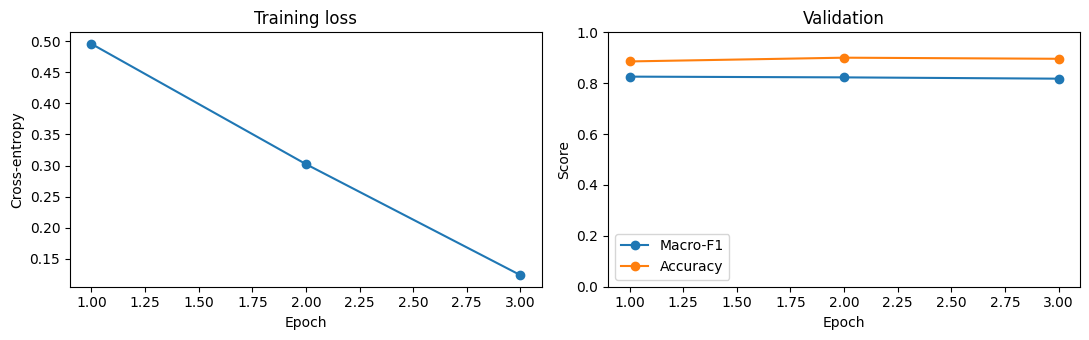

Checkpoint: /content/outputs/resume.zip (6.34 GB)
Next session: upload this archive with the SAME immutable payload.


In [6]:
display(pd.DataFrame(trainer.state['history']))
plot_history(trainer.state['history'], output_path=OUTPUT_ROOT / 'training_curves.png')
checkpoint = OUTPUT_ROOT / 'resume.zip'
print(f'Checkpoint: {checkpoint} ({checkpoint.stat().st_size / 1e9:.2f} GB)')
print('Next session: upload this archive with the SAME immutable payload.')

# The cloud CLI downloads all outputs automatically before releasing the runtime.
# Interactive Colab only: opt in to a browser download.
DOWNLOAD_CHECKPOINT = False
if DOWNLOAD_CHECKPOINT and not HEADLESS and Path('/content').exists():
    from google.colab import files
    files.download(str(checkpoint))